# Heart Disease Prediction

## A Machine Learning Approach for 10-Year Coronary Heart Disease Prediction Using the Framingham Heart Study Dataset

This notebook is the analysis companion to the project. It covers dataset inspection, exploratory data analysis, data quality assessment, preprocessing design, five-model training and comparison, threshold selection, and final model artefacts.

## Running in Google Colab

In Colab, do **not** double-click the `.ipynb` in the Files panel; that downloads the file. Use **File → Upload notebook** and select `notebooks/heart_disease_analysis.ipynb` from your locally unzipped project folder.

The first code cell then asks you to upload `heart-disease-prediction.zip` if the full project is not already under `/content`. The next cell extracts it, detects Colab, locates the project at `/content/heart-disease-prediction`, installs `requirements.txt`, and sets `PROJECT_ROOT`.

Alternatively, place the project folder in Google Drive at `MyDrive/heart-disease-prediction`; the setup cell mounts Drive automatically when needed.

In [1]:
from pathlib import Path
import subprocess
import sys

if "google.colab" in sys.modules and not Path("/content/heart-disease-prediction/src/config.py").exists():
    from google.colab import files
    print("Upload heart-disease-prediction.zip when prompted.")
    uploaded = files.upload()
    zip_path = Path("/content") / next(iter(uploaded))
    subprocess.check_call(["unzip", "-o", str(zip_path), "-d", "/content"])
    print("Extracted to /content/heart-disease-prediction")
else:
    print("Colab upload not needed or running locally.")


Colab upload not needed or running locally.


## A. Introduction

**Objective.** Predict whether a participant developed coronary heart disease (CHD) within ten years from baseline demographic and health measurements, and compare five machine-learning algorithms.

**Target.** `TenYearCHD`: `0` = no recorded CHD event during follow-up, `1` = CHD developed during follow-up.

**Primary modelling goal.** Reduce false negatives (missed positive cases) while maintaining reasonable specificity and precision. Increasing recall usually increases false positives; this trade-off is measured rather than ignored.

**Approach.** A stratified 80/20 train-test split, five-fold stratified cross-validation, GridSearchCV for hyperparameter tuning, out-of-fold validation predictions for threshold selection, and a single final evaluation on the untouched test set.

**Scope.** The outcome is the historical ten-year CHD outcome in this dataset. It is not a diagnosis of heart attacks, heart failure, or all cardiovascular diseases, and it is not the MDCalc Framingham Hard CHD Risk Score.

In [2]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    candidates = [
        Path("/content/heart-disease-prediction"),
        Path("/content/drive/MyDrive/heart-disease-prediction"),
    ]
    PROJECT_ROOT = next(
        (p for p in candidates if (p / "src" / "config.py").exists()), None
    )
    if PROJECT_ROOT is None:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path("/content/drive/MyDrive/heart-disease-prediction")
    if not (PROJECT_ROOT / "src" / "config.py").exists():
        raise FileNotFoundError(
            "Upload/unzip the project to /content/heart-disease-prediction "
            "or place it in Drive at MyDrive/heart-disease-prediction."
        )
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_ROOT / "requirements.txt")]
    )
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import (  # noqa: E402
    BINARY_FEATURES,
    FEATURE_COLUMNS,
    FIGURES_DIR,
    MODELS_DIR,
    NUMERIC_FEATURES,
    TARGET_COLUMN,
)
from preprocessing import (  # noqa: E402
    build_preprocessor,
    dataset_summary,
    load_dataset,
    separate_features_target,
    stratified_train_test_split,
)

sns.set_theme(style="whitegrid", palette="deep")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
print("Project root:", PROJECT_ROOT)

Project root: /home/rushikesh/heart-disease-prediction


## B. Dataset inspection

The dataset is loaded from the provided CSV without replacing it. The `NA` strings in the source file are read as missing values.

In [3]:
df = load_dataset(PROJECT_ROOT / "data" / "framingham.csv")

print("First five rows:")
display(df.head())
print("Last five rows:")
display(df.tail())
print("\nDimensions:", df.shape)
print("Columns:", list(df.columns))
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nStatistical summary:")
display(df.describe().T)

First five rows:


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


Last five rows:


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0



Dimensions: (4240, 16)
Columns: ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

Data types:


,dtype
male,int64
age,int64
education,float64
currentSmoker,int64
cigsPerDay,float64
BPMeds,float64
prevalentStroke,int64
prevalentHyp,int64
diabetes,int64
totChol,float64



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


In [4]:
missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
print("Missing values:")
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nUnique values per column:")
display(df.nunique(dropna=True).rename("unique_values").to_frame())

print("\nTarget distribution:")
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
target_percent = df[TARGET_COLUMN].value_counts(normalize=True).sort_index().mul(100).round(2)
display(pd.DataFrame({"count": target_counts, "percent": target_percent}))

print("\nDataset facts:")
display(pd.Series(dataset_summary(df), dtype=object).to_frame("value"))

Missing values:


,missing_count,missing_percent
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


Exact duplicate rows: 0

Unique values per column:


,unique_values
male,2
age,39
education,4
currentSmoker,2
cigsPerDay,33
BPMeds,2
prevalentStroke,2
prevalentHyp,2
diabetes,2
totChol,248



Target distribution:


,count,percent
TenYearCHD,,
0,3596,84.81
1,644,15.19



Dataset facts:


,value
n_records,4240
n_columns,16
n_features,15
target_column,TenYearCHD
negative_cases,3596
positive_cases,644
positive_class_proportion,0.151887
duplicate_rows,0
missing_values,"{'education': 105, 'cigsPerDay': 29, 'BPMeds':..."
age_range,"[32, 70]"


**Interpretation.** The dataset contains 4,240 records and no duplicate rows. The positive class is a minority (~15.2%), so accuracy alone would be misleading. Missing values are concentrated in a small number of columns, with glucose having the largest count. No rows are deleted; imputation is fitted inside training folds later.

## C. Exploratory Data Analysis

All charts below are generated from the actual CSV. Interpretations describe observed sample patterns only; correlations do not establish medical causation.

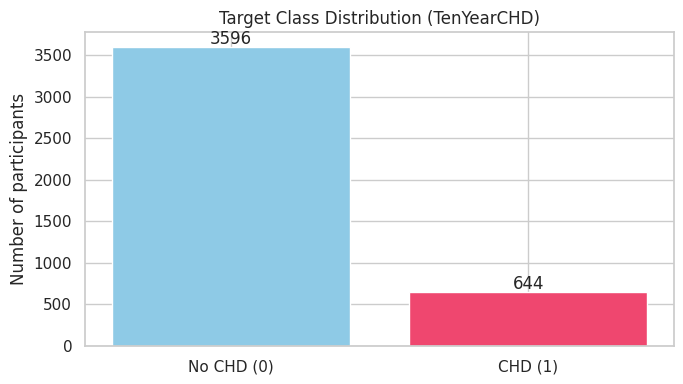

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df[TARGET_COLUMN].value_counts().sort_index()
bars = ax.bar(["No CHD (0)", "CHD (1)"], counts.values, color=["#8ecae6", "#ef476f"])
ax.set_title("Target Class Distribution (TenYearCHD)")
ax.set_ylabel("Number of participants")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 40, str(value), ha="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "target_distribution.png", dpi=160)
plt.show()

**Interpretation.** Negative cases substantially outnumber positive cases. This imbalance motivates stratified splitting and recall-focused evaluation.

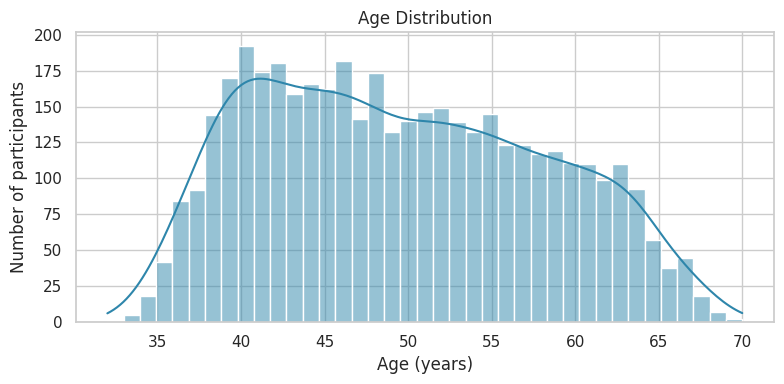

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="age", bins=39, kde=True, color="#2E86AB", ax=ax)
ax.set_title("Age Distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of participants")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "age_distribution.png", dpi=160)
plt.show()

**Interpretation.** Ages are restricted to 32–70 years. The prediction form enforces this observed range because the model has no evidence of validity outside it.

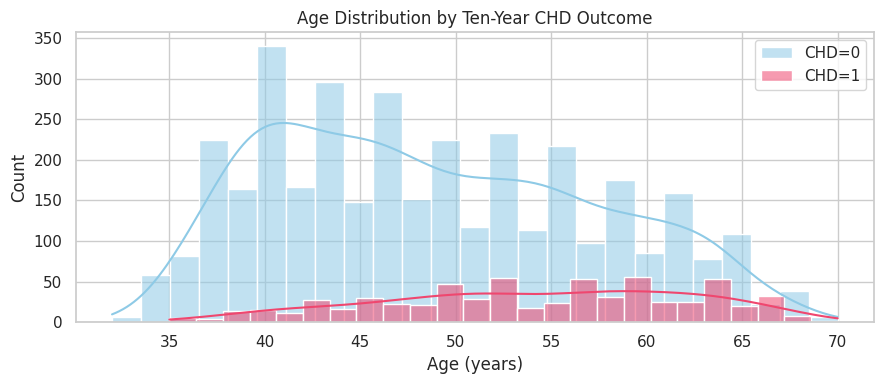

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, color in [(0, "#8ecae6"), (1, "#ef476f")]:
    subset = df[df[TARGET_COLUMN] == label]
    sns.histplot(subset["age"], bins=25, kde=True, color=color, label=f"CHD={label}", ax=ax, alpha=0.55)
ax.set_title("Age Distribution by Ten-Year CHD Outcome")
ax.set_xlabel("Age (years)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "age_by_target.png", dpi=160)
plt.show()

**Interpretation.** In this sample, the age distribution shifts towards older participants among positive cases. This is an association in the observed data, not proof of causation.

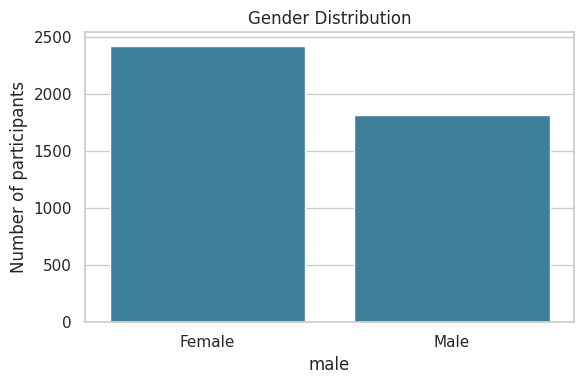

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
gender_counts = df["male"].map({0: "Female", 1: "Male"}).value_counts()
sns.barplot(x=gender_counts.index, y=gender_counts.values, color="#2E86AB", ax=ax)
ax.set_title("Gender Distribution")
ax.set_ylabel("Number of participants")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gender_distribution.png", dpi=160)
plt.show()

**Interpretation.** The sample contains both sexes, with slightly more female participants.

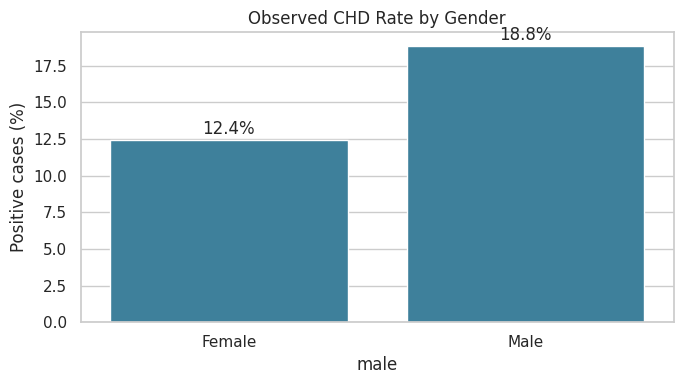

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
chd_by_gender = df.groupby("male")[TARGET_COLUMN].mean().rename(index={0: "Female", 1: "Male"}) * 100
sns.barplot(x=chd_by_gender.index, y=chd_by_gender.values, color="#2E86AB", ax=ax)
ax.set_title("Observed CHD Rate by Gender")
ax.set_ylabel("Positive cases (%)")
for index, value in enumerate(chd_by_gender.values):
    ax.text(index, value + 0.4, f"{value:.1f}%", ha="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "chd_by_gender.png", dpi=160)
plt.show()

**Interpretation.** Observed positive-case rates differ by sex in this cohort. The model uses sex as one of 15 inputs and does not isolate its independent effect here.

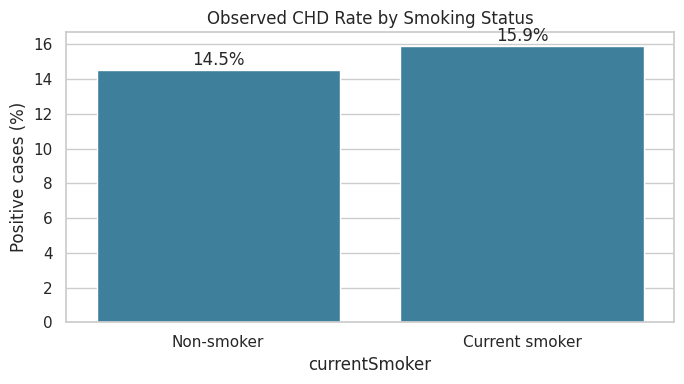

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
smoking_chd = df.groupby("currentSmoker")[TARGET_COLUMN].mean().rename(index={0: "Non-smoker", 1: "Current smoker"}) * 100
sns.barplot(x=smoking_chd.index, y=smoking_chd.values, color="#2E86AB", ax=ax)
ax.set_title("Observed CHD Rate by Smoking Status")
ax.set_ylabel("Positive cases (%)")
for index, value in enumerate(smoking_chd.values):
    ax.text(index, value + 0.3, f"{value:.1f}%", ha="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "smoking_chd.png", dpi=160)
plt.show()

**Interpretation.** The chart compares raw observed rates by smoking status without adjusting for age or other variables.

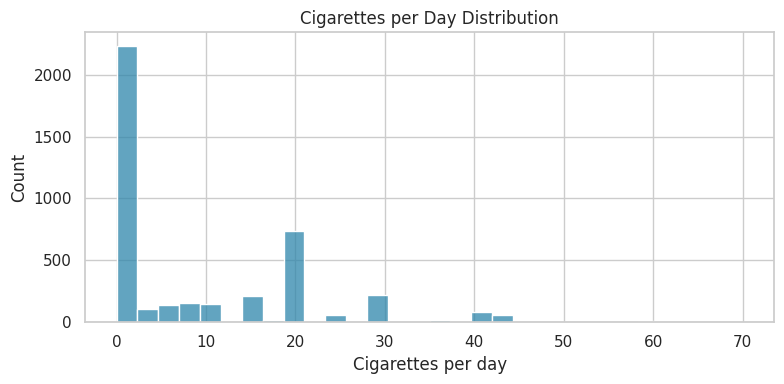

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="cigsPerDay", bins=30, color="#2E86AB", ax=ax)
ax.set_title("Cigarettes per Day Distribution")
ax.set_xlabel("Cigarettes per day")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cigs_per_day_distribution.png", dpi=160)
plt.show()

**Interpretation.** The distribution has a large spike at zero because non-smokers are included. Median imputation is used for the small number of missing values.

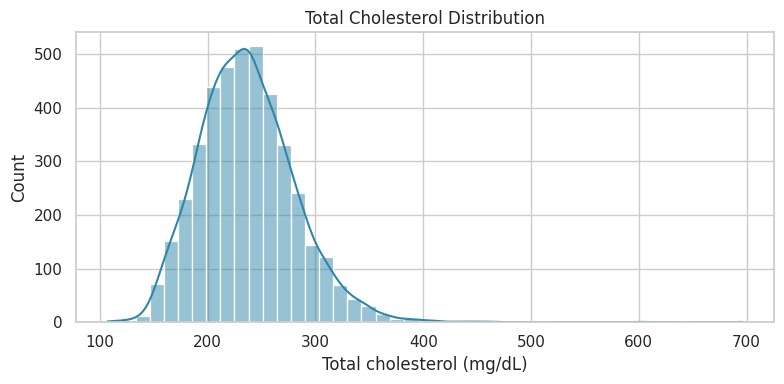

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="totChol", bins=45, kde=True, color="#2E86AB", ax=ax)
ax.set_title("Total Cholesterol Distribution")
ax.set_xlabel("Total cholesterol (mg/dL)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cholesterol_distribution.png", dpi=160)
plt.show()

**Interpretation.** Most values are concentrated in the middle of the observed range, with a few high values that the imputation-and-scaling pipeline retains rather than removes.

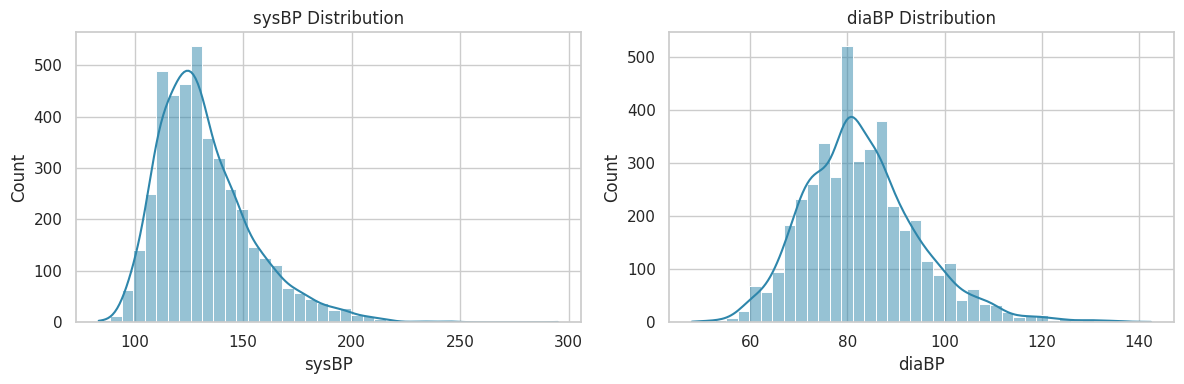

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, ax in [("sysBP", axes[0]), ("diaBP", axes[1])]:
    sns.histplot(data=df, x=column, bins=40, kde=True, color="#2E86AB", ax=ax)
    ax.set_title(f"{column} Distribution")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "blood_pressure_distributions.png", dpi=160)
plt.show()

**Interpretation.** Systolic and diastolic blood pressure are both recorded as continuous measurements. Their distributions are right-skewed; no clinical thresholds are applied in the model.

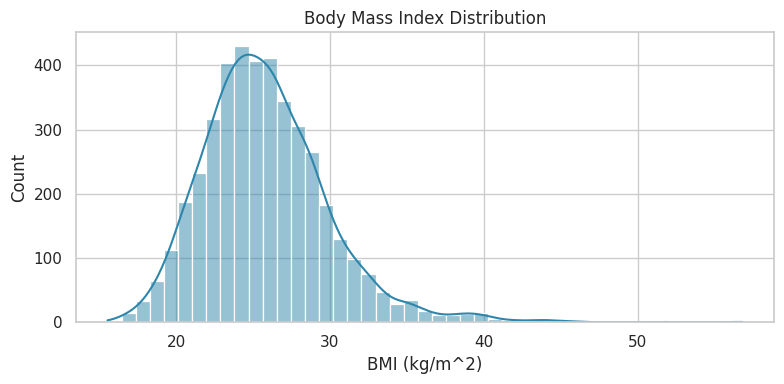

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="BMI", bins=45, kde=True, color="#2E86AB", ax=ax)
ax.set_title("Body Mass Index Distribution")
ax.set_xlabel("BMI (kg/m^2)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bmi_distribution.png", dpi=160)
plt.show()

**Interpretation.** BMI is approximately centred near the mid-20s with a right tail. Missing BMI values are imputed inside cross-validation folds.

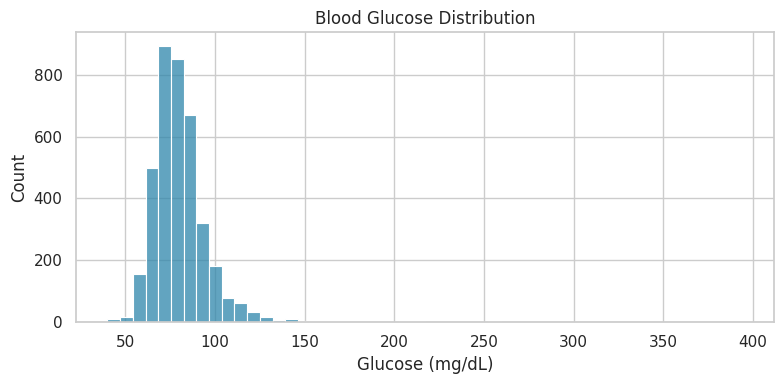

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="glucose", bins=50, color="#2E86AB", ax=ax)
ax.set_title("Blood Glucose Distribution")
ax.set_xlabel("Glucose (mg/dL)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "glucose_distribution.png", dpi=160)
plt.show()

**Interpretation.** Glucose has the highest number of missing values and a pronounced right tail. The model imputes missing values with the training-fold median; the chart reflects raw available observations only.

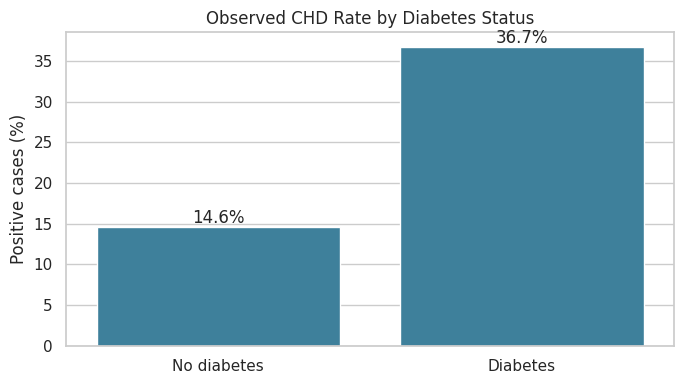

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
diabetes_chd = df.groupby("diabetes")[TARGET_COLUMN].mean() * 100
sns.barplot(x=["No diabetes", "Diabetes"], y=diabetes_chd.values, color="#2E86AB", ax=ax)
ax.set_title("Observed CHD Rate by Diabetes Status")
ax.set_ylabel("Positive cases (%)")
for index, value in enumerate(diabetes_chd.values):
    ax.text(index, value + 0.5, f"{value:.1f}%", ha="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "diabetes_chd.png", dpi=160)
plt.show()

**Interpretation.** The diabetes group is small in this dataset, so its observed rate is less stable than the larger groups. No medical conclusion is inferred from this unadjusted comparison.

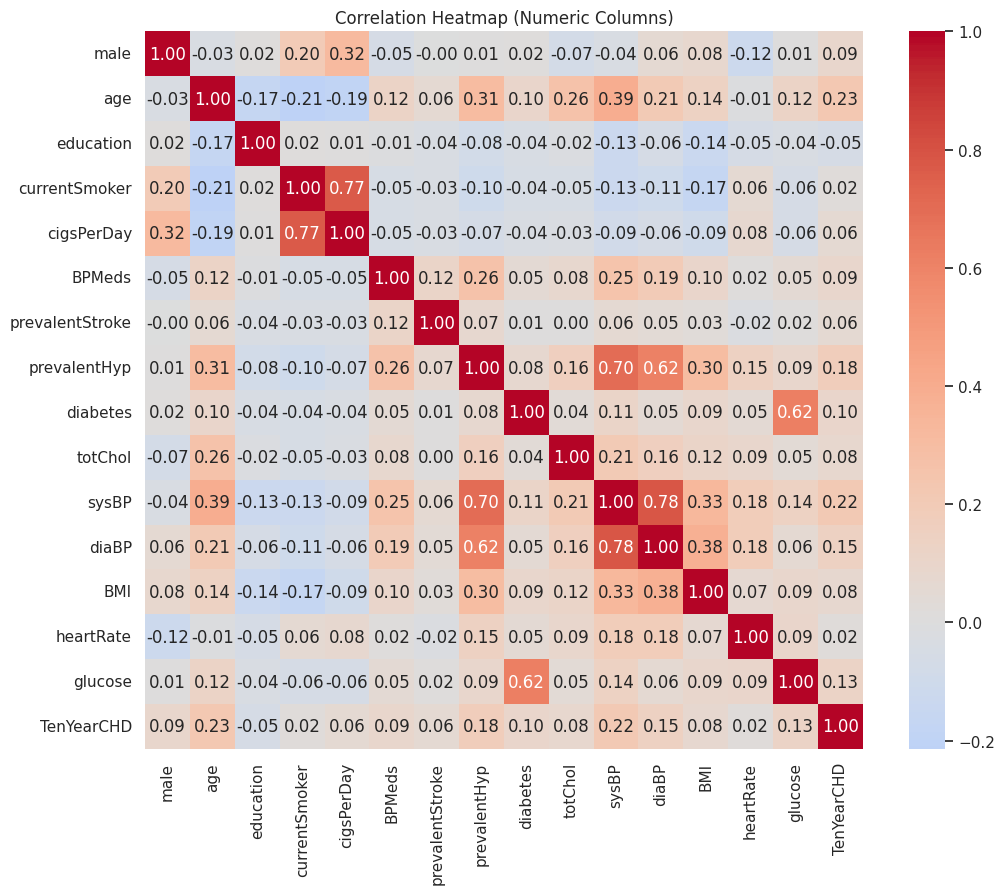

In [17]:
correlation = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Heatmap (Numeric Columns)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=160)
plt.show()

**Interpretation.** The heatmap shows linear associations among recorded variables. Correlated predictors may carry overlapping information; correlation does not imply causation and does not by itself justify removing a feature.

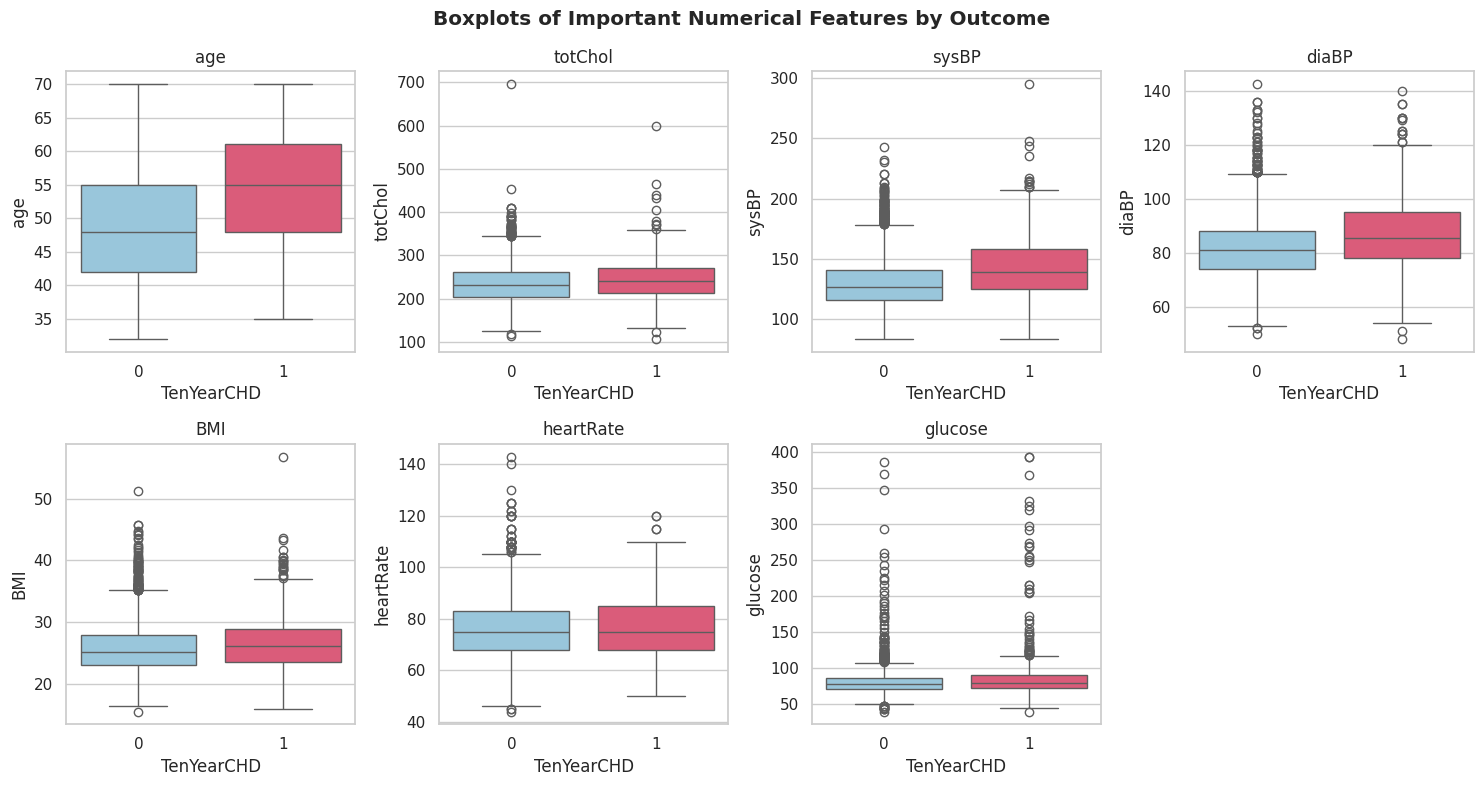

In [18]:
box_features = ["age", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, column in zip(axes.ravel(), box_features):
    sns.boxplot(data=df, x=TARGET_COLUMN, y=column, ax=ax, palette=["#8ecae6", "#ef476f"])
    ax.set_title(column)
    ax.set_xlabel("TenYearCHD")
axes.ravel()[-1].axis("off")
fig.suptitle("Boxplots of Important Numerical Features by Outcome", weight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_boxplots_by_target.png", dpi=160)
plt.show()

**Interpretation.** Boxplots display group-wise distributions and outliers. Differences shown here are descriptive and are not adjusted for the other features.

,Mean when CHD=0,Mean when CHD=1
age,48.76,54.15
cigsPerDay,8.71,10.63
totChol,235.15,245.39
sysBP,130.34,143.62
diaBP,82.17,86.98
BMI,25.67,26.53
heartRate,75.76,76.53
glucose,80.68,89.01


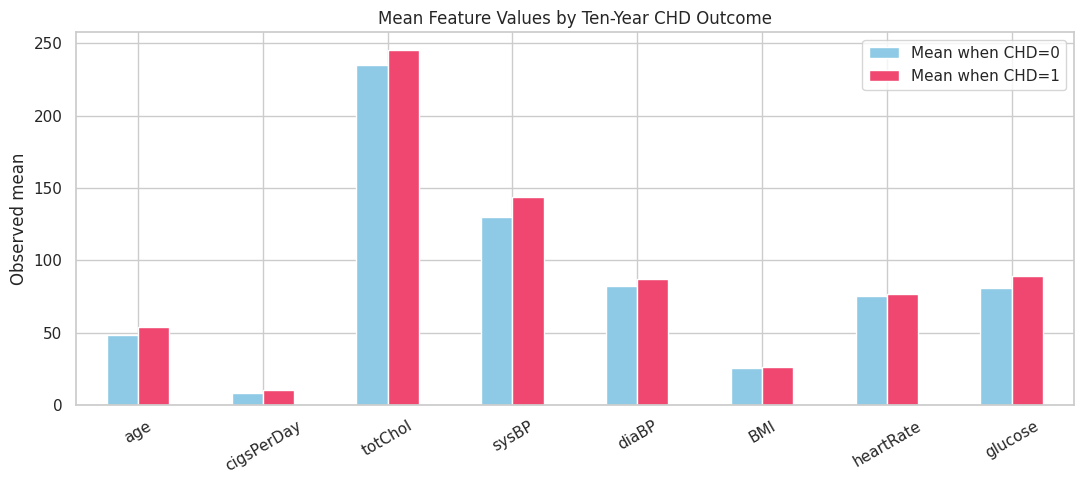

In [19]:
comparison_features = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
group_means = df.groupby(TARGET_COLUMN)[comparison_features].mean().T
group_means.columns = ["Mean when CHD=0", "Mean when CHD=1"]
display(group_means.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
group_means.plot(kind="bar", ax=ax, color=["#8ecae6", "#ef476f"])
ax.set_title("Mean Feature Values by Ten-Year CHD Outcome")
ax.set_ylabel("Observed mean")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_comparison_by_target.png", dpi=160)
plt.show()

**Interpretation.** These are unadjusted group means. They help describe the dataset but are not effect estimates and must not be read as medical risk conclusions.

## D. Data quality analysis

Missing values are handled with pipeline imputation. Binary and numeric fields use training-fold medians/modes; `education` is treated as an ordered category with an explicit `0 = unknown` level rather than as a continuous measurement. No high-missingness column or large block of rows is discarded.

In [20]:
quality = df.isna().sum().rename("missing_count").to_frame()
quality = quality[quality["missing_count"] > 0].sort_values("missing_count", ascending=False)
quality["percent_of_rows"] = (quality["missing_count"] / len(df) * 100).round(2)
quality["handling"] = "Imputed inside each training/CV fold"
quality.loc["education", "handling"] = "Explicit unknown category (0) + one-hot encoding"
display(quality)

print("Education values including missing:")
display(df["education"].value_counts(dropna=False).sort_index().to_frame("count"))

,missing_count,percent_of_rows,handling
glucose,388,9.15,Imputed inside each training/CV fold
education,105,2.48,Explicit unknown category (0) + one-hot encoding
BPMeds,53,1.25,Imputed inside each training/CV fold
totChol,50,1.18,Imputed inside each training/CV fold
cigsPerDay,29,0.68,Imputed inside each training/CV fold
BMI,19,0.45,Imputed inside each training/CV fold
heartRate,1,0.02,Imputed inside each training/CV fold


Education values including missing:


,count
education,
1.0,1720
2.0,1253
3.0,689
4.0,473
NaN,105


**Interpretation.** Glucose is missing for a substantial minority of records, which may limit any conclusions involving that feature. The chosen strategy keeps every row while ensuring imputation statistics are learned from training data only.

## E. Preprocessing and modelling workflow

The same `build_preprocessor` function used by the training script is applied here. It is fitted only on the training portion. Separate scaled and unscaled variants are provided for models that need standardisation and tree-based models that do not.

In [21]:
X, y = separate_features_target(df)
X_train, X_test, y_train, y_test = stratified_train_test_split(X, y)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate: ", round(y_test.mean(), 4))

scaled_preprocessor = build_preprocessor(scale_numeric=True)
scaled_preprocessor.fit(X_train)
print("Transformed columns (scaled pipeline):")
print(list(scaled_preprocessor.get_feature_names_out()))

Train shape: (3392, 15) | Test shape: (848, 15)
Train positive rate: 0.1518
Test positive rate:  0.1521
Transformed columns (scaled pipeline):
['numeric__age', 'numeric__cigsPerDay', 'numeric__totChol', 'numeric__sysBP', 'numeric__diaBP', 'numeric__BMI', 'numeric__heartRate', 'numeric__glucose', 'binary__male', 'binary__currentSmoker', 'binary__BPMeds', 'binary__prevalentStroke', 'binary__prevalentHyp', 'binary__diabetes', 'education__education_0.0', 'education__education_1.0', 'education__education_2.0', 'education__education_3.0', 'education__education_4.0']


**Interpretation.** Train and test positive rates are nearly identical, confirming that stratification preserved the class balance. The fitted preprocessor output names show that education became five one-hot columns and all 15 source features are represented.

## F. Training, tuning and model comparison

`RUN_TRAINING` is set to `False` so that opening/executing the notebook loads the saved artefacts instead of retraining. Set it to `True` to reproduce the complete five-model GridSearchCV workflow from the notebook. Hyperparameters, thresholds and the final test metric are never recomputed from the test set for selection.

In [22]:
RUN_TRAINING = False

if RUN_TRAINING:
    from train_models import run_training_pipeline
    pipeline_result = run_training_pipeline()
    comparison_table = pipeline_result["comparison"]
else:
    comparison_table = pd.read_csv(MODELS_DIR / "model_comparison.csv")

display(comparison_table.round(4))

,model,threshold,accuracy,precision,recall,specificity,f1_score,false_negative_rate,roc_auc,pr_auc,cv_best_mean_recall
0,Logistic Regression,0.4288,0.5625,0.2316,0.8117,0.5179,0.3603,0.1883,0.7301,0.3491,0.7029
1,Decision Tree,0.4806,0.5545,0.2186,0.7515,0.5193,0.3387,0.2485,0.6777,0.2502,0.7359
2,Random Forest,0.3292,0.5486,0.2233,0.7961,0.5043,0.3488,0.2039,0.7150,0.3256,0.4505
3,Support Vector Machine,0.1062,0.5486,0.2257,0.8117,0.5016,0.3532,0.1883,0.7228,0.2990,0.7223
4,XGBoost,0.4061,0.5457,0.2206,0.7864,0.5026,0.3445,0.2136,0.7140,0.3245,0.6369


## G. Threshold and result interpretation

The decision threshold is selected from out-of-fold training predictions, not from the test set. The ranking prioritises recall while requiring reasonable specificity and precision, and records the false-positive trade-off explicitly.

In [23]:
metadata = json.loads((MODELS_DIR / "model_metadata.json").read_text(encoding="utf-8"))
evaluation = json.loads((MODELS_DIR / "evaluation_results.json").read_text(encoding="utf-8"))

print("Selected model:", metadata["selected_model"])
print("Default threshold:", metadata["default_threshold"])
print("Selected threshold:", metadata["decision_threshold"])
print("Threshold reason:", metadata["threshold_selection"]["reason"])
print("Model selection reason:", metadata["model_selection_method"])

validation_metrics = metadata["validation_metrics"]
print("\nValidation metrics at selected threshold:")
display(pd.Series(validation_metrics, dtype=object).to_frame("value"))

if metadata.get("final_test_metrics"):
    print("\nFinal test metrics (single evaluation):")
    display(pd.Series(metadata["final_test_metrics"], dtype=object).to_frame("value"))

Selected model: Logistic Regression
Default threshold: 0.5
Selected threshold: 0.4288
Threshold reason: Maximum validation recall among thresholds meeting the pre-declared specificity >= 0.50 and precision >= 0.20 floors; ties broken by F1 and specificity.
Model selection reason: Models meeting specificity >= 0.50 and precision >= 0.20 were ranked by recall, then PR-AUC, F1-score, specificity and precision.

Validation metrics at selected threshold:


,value
threshold,0.4288
accuracy,0.5625
precision,0.231579
recall,0.81165
specificity,0.517901
f1_score,0.360345
false_negative_rate,0.18835
roc_auc,0.730051
pr_auc,0.349071
true_negative,1490



Final test metrics (single evaluation):


,value
threshold,0.4288
accuracy,0.567217
precision,0.223256
recall,0.744186
specificity,0.535466
f1_score,0.34347
false_negative_rate,0.255814
roc_auc,0.695583
pr_auc,0.291057
true_negative,385


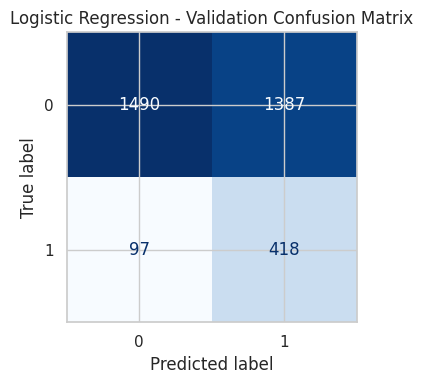

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

selected_metrics = evaluation["validation_results"][metadata["selected_model"]]["validation_metrics"]
matrix = np.array([
    [selected_metrics["true_negative"], selected_metrics["false_positive"]],
    [selected_metrics["false_negative"], selected_metrics["true_positive"]],
])
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=["0", "1"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title(f"{metadata['selected_model']} - Validation Confusion Matrix")
fig.tight_layout()
plt.show()

**Interpretation.** False negatives are reduced relative to the default threshold, but they are not eliminated. A lower threshold also increases false positives, which is why specificity and precision are reported alongside recall.

## H. Limitations and disclaimer

- The Framingham dataset used here is a historical cohort sample; its `TenYearCHD` outcome is not identical to the MDCalc Framingham Hard CHD Risk Score.
- The model is validated only on participants aged 32–70 with measurements similar to this dataset.
- Missing glucose and other values were imputed; imputation introduces uncertainty.
- The website is an academic machine-learning demonstration, not a clinically validated risk calculator, diagnosis, or substitute for professional medical advice.